# Taller 2. Predicción de abandono (churn) de clientes
## Notebook 3 de 3. Generación de valor

**MINE-4101 Ciencia de Datos Aplicada, Universidad de los Andes, 2026-20**

**Integrantes:**
* Lina Muñoz (202310172)
* Yair Andrade (202310241)

**Requisito.** Ejecutar antes `01_entendimiento_preparacion.ipynb`, que genera `data/churn_limpio.csv`.

**Pregunta.** ¿Cuánto gana un banco colombiano promedio si usa el modelo para decidir a quién ofrecerle una campaña de retención, y en cuánto tiempo recupera la inversión?

**Contenido**
* 0. Configuración
* 5. Generación de valor
  * 5.1 Planteamiento
  * 5.2 Supuestos y matriz de costo-beneficio
  * 5.3 Modelos
  * 5.4 Valor esperado (fórmula de Provost)
  * 5.5 Fórmula simplificada y precisión de equilibrio
  * 5.6 Elección del umbral
  * 5.7 Inversión, punto de equilibrio y ROI
  * 5.8 Recuperar la inversión en 12 meses
  * 5.9 Limitaciones
  * 5.10 Conclusiones y recomendaciones

## 0. Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

SEED = 42

## 5. Generación de valor

### 5.1 Planteamiento

El banco usaría el modelo para decidir a quién contactar en una campaña de retención. Cada contacto cuesta, y la oferta solo convence al 30% de los clientes que se iban a ir. Si el cliente se iba a quedar, el contacto no cambia nada.

Seguimos los pasos de la actividad 3 de la práctica 4:
1. Matriz de costo-beneficio frente a no usar el modelo.
2. Valor esperado por cliente con la fórmula de Provost.
3. Ganancia por cliente contactado ($\hat{a}$) y precisión de equilibrio.
4. Umbral que da más beneficio: lo elegimos en validación y medimos el resultado en prueba.
5. Punto de equilibrio y ROI a 12 meses.
6. Recall mínimo para recuperar la inversión en 12 meses.

### 5.2 Supuestos y matriz de costo-beneficio

| Supuesto | Símbolo | Valor | Fuente |
|---|---|---|---|
| Clientes del banco | $N$ | 20.000 | Enunciado |
| Tasa de churn anual | $p(p)$ | 15% | Enunciado |
| Efectividad de la oferta | $r$ | 30% | Enunciado |
| Valor de un cliente retenido (ingreso anual) | $V$ | COP 700.000 | Enunciado; [reporte de Nu, 1T 2026](https://www.sec.gov/Archives/edgar/data/1691493/000129281426003055/nu20260514_6k.htm) |
| Costo por cliente contactado | $c$ | COP 40.000 | [FusionCX](https://www.fusioncx.com/blog/locations/colombia/colombia-call-center-costs-2026-b2b-buyer-guide/), [Bancolombia](https://www.bancolombia.com/personas/tarifario/tarjeta-de-credito) |
| Inversión del proyecto | $I_{\text{proy}}$ | COP 148 M | Sección 5.7 |
| Costo de operación al año | $O$ | COP 50 M | Supuesto nuestro |

* **Churn y efectividad de la oferta.** Usamos los valores del enunciado. No encontramos mediciones para bancos colombianos.
* **Valor de un cliente retenido.** Es el punto medio del rango del enunciado (COP 500.000 a 900.000). Se parece a lo que gana Nu por cliente activo: US\$15,9 al mes, unos COP 708.500 al año. Suponemos que un cliente retenido se queda al menos un año más.
* **Costo por contacto.** Es una llamada más un incentivo. Un agente de call center en Colombia cuesta desde US\$12 la hora según FusionCX; con 4 llamadas por hora, cada una sale en unos COP 9.700. El incentivo es un mes gratis de cuota de manejo de la tarjeta de crédito, COP 30.900 en Bancolombia.
* **Operación.** La práctica 4 pregunta por los costos que se repiten después del lanzamiento. Contamos un cuarto del tiempo de una persona más la nube, unos COP 50 M al año.

**Matriz de costo-beneficio.** Le damos un valor en pesos a cada casilla de la matriz de confusión, frente a no usar el modelo. Las mayúsculas son la predicción y las minúsculas, la realidad:

| Casilla | Qué pasa | Valor |
|---|---|---|
| $b(P,p)$, verdadero positivo | Se iba a ir, se le contacta y se queda con probabilidad $r$ | $rV - c$ |
| $c(P,n)$, falso positivo | No se iba a ir, pero se le contacta | $-c$ |
| $c(N,p)$, falso negativo | Se va sin ser contactado, igual que sin modelo | $0$ |
| $b(N,n)$, verdadero negativo | No se iba a ir y no se le contacta | $0$ |

In [2]:
N = 20_000      # clientes del banco
p_p = 0.15      # tasa de churn anual del banco, p(p)
p_n = 1 - p_p   # p(n)
r = 0.30        # efectividad de la oferta
V = 700_000     # ingreso anual por cliente (COP)
c = 40_000      # costo por cliente contactado (COP)
O = 50_000_000  # costo de operación del modelo al año (COP)

# Matriz de costo-beneficio (COP por cliente), frente a no usar el modelo
b_Pp = r * V - c   # verdadero positivo
c_Pn = -c          # falso positivo
c_Np = 0           # falso negativo
b_Nn = 0           # verdadero negativo

matriz = pd.DataFrame(
    {"Positivo (p)": [b_Pp, c_Np], "Negativo (n)": [c_Pn, b_Nn]},
    index=["Positivo (P)", "Negativo (N)"],
).astype(int)
matriz.index.name = "Predicción \\ Realidad"
matriz

,Positivo (p),Negativo (n)
Predicción \ Realidad,,
Positivo (P),170000,-40000
Negativo (N),0,0


Un contacto acertado deja **COP 170.000** ($rV - c$) y uno equivocado cuesta COP 40.000.

### 5.3 Modelos

Reentrenamos el Random Forest y el Gradient Boosting con los hiperparámetros de la sección 2.7 del notebook 2, con la misma división de datos y la misma semilla.

In [3]:
df = pd.read_csv("data/churn_limpio.csv")
df = pd.get_dummies(df, columns=["country", "gender"], dtype=int)

ATRIBUTOS = [
    "credit_score", "age", "tenure", "balance", "products_number",
    "credit_card", "active_member", "estimated_salary",
    "country_France", "country_Germany", "country_Spain",
    "gender_Female", "gender_Male",
]
X = df[ATRIBUTOS]
y = df["churn"]

# Misma división 60/20/20 y misma semilla
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
y_val = np.asarray(y_val)
y_test = np.asarray(y_test)

# Hiperparámetros de la sección 2.7 del notebook 2
modelos = {
    "Random Forest": RandomForestClassifier(
        n_estimators=500, max_depth=15, min_samples_leaf=5, max_features=0.5,
        class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.01, max_depth=6, max_iter=500, min_samples_leaf=20,
        l2_regularization=1, class_weight="balanced", random_state=SEED),
}

prob_val = {}
prob_test = {}
filas = []
for nombre in modelos:
    pipeline = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("modelo", modelos[nombre]),
    ])
    pipeline.fit(X_train, y_train)
    prob_val[nombre] = pipeline.predict_proba(X_val)[:, 1]
    prob_test[nombre] = pipeline.predict_proba(X_test)[:, 1]

    y_pred = prob_test[nombre] >= 0.5
    filas.append({
        "modelo": nombre,
        "F1": f1_score(y_test, y_pred),
        "Precisión": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, prob_test[nombre]),
    })

pd.DataFrame(filas).set_index("modelo").round(3)

,F1,Precisión,Recall,ROC-AUC
modelo,,,,
Random Forest,0.633,0.673,0.597,0.867
Gradient Boosting,0.600,0.504,0.742,0.867


Las métricas cambian frente al notebook 2 solo en el tercer decimal (F1 de 0,633 en vez de 0,637; ver la nota de reproducibilidad de la sección 3.3 del notebook 2).

### 5.4 Valor esperado (fórmula de Provost)

La muestra tiene 20% de churn, pero el banco tiene 15%. Por eso no usamos la matriz de confusión de la muestra tal cual, sino la fórmula de Provost con las proporciones del banco, las **distribuciones previas** $p(p) = 0{,}15$ y $p(n) = 0{,}85$:

$$\text{Valor esperado} = p(p)\,\big[p(P|p)\cdot b(P,p) + p(N|p)\cdot c(N,p)\big] + p(n)\,\big[p(N|n)\cdot b(N,n) + p(P|n)\cdot c(P,n)\big]$$

* $p(P|p)$ es el **recall**: de los clientes que se van, qué fracción contactamos.
* $p(P|n)$ es el **fall-out**: de los clientes que se quedan, qué fracción contactamos.

Como $c(N,p)$ y $b(N,n)$ valen 0, quedan dos términos:

$$\text{Valor esperado} = 0{,}15 \cdot p(P|p) \cdot (rV - c) - 0{,}85 \cdot p(P|n) \cdot c$$

El beneficio mensual es el valor esperado por los $N$ clientes del banco, dividido en 12. Empezamos con el umbral de 0,5 en prueba.

In [4]:
def tasas(y_real, prob, umbral):
    """Devuelve el recall p(P|p) y el fall-out p(P|n) con un umbral"""
    contactar = prob >= umbral
    recall = contactar[y_real == 1].mean()
    fall_out = contactar[y_real == 0].mean()
    return recall, fall_out


def valor_esperado(recall, fall_out):
    """Fórmula de Provost con las proporciones del banco (COP por cliente)"""
    positivos = recall * b_Pp + (1 - recall) * c_Np
    negativos = (1 - fall_out) * b_Nn + fall_out * c_Pn
    return p_p * positivos + p_n * negativos


def beneficio_mensual(recall, fall_out):
    """Beneficio de la campaña al mes en todo el banco (COP)"""
    return N * valor_esperado(recall, fall_out) / 12


def precision_banco(recall, fall_out):
    """Precisión con las proporciones del banco"""
    return p_p * recall / (p_p * recall + p_n * fall_out)


filas = []
for nombre in modelos:
    recall, fall_out = tasas(y_test, prob_test[nombre], 0.5)
    y_pred = prob_test[nombre] >= 0.5
    ve = valor_esperado(recall, fall_out)
    filas.append({
        "modelo": nombre,
        "recall p(P|p)": recall,
        "fall-out p(P|n)": fall_out,
        "precisión en la muestra": precision_score(y_test, y_pred),
        "precisión en el banco": precision_banco(recall, fall_out),
        "valor esperado por cliente (COP)": round(ve),
        "beneficio mensual (M COP)": beneficio_mensual(recall, fall_out) / 1e6,
    })
pd.DataFrame(filas).set_index("modelo").round(3)

,recall p(P|p),fall-out p(P|n),precisión en la muestra,precisión en el banco,valor esperado por cliente (COP),beneficio mensual (M COP)
modelo,,,,,,
Random Forest,0.597,0.074,0.673,0.587,12706,21.177
Gradient Boosting,0.742,0.186,0.504,0.413,12582,20.971


* Con umbral 0,5 los dos modelos dejan casi lo mismo: **COP 12.706 por cliente** el Random Forest y COP 12.582 el Gradient Boosting, unos **COP 21 M al mes**.
* El Random Forest encuentra menos clientes que se van (recall de 59,7% frente a 74,2%), pero también contacta a muchos menos que se iban a quedar (fall-out de 7,4% frente a 18,6%).
* La precisión del Random Forest baja de 67,3% en la muestra a **58,7% en el banco**, porque en el banco se van menos clientes.

### 5.5 Fórmula simplificada y precisión de equilibrio

$$\hat{a} = a - (1 - I) \cdot e$$

En la campaña solo cuentan los clientes contactados, así que $I$ es la precisión $P$, $a = rV - c$ es lo que deja un contacto acertado y $e = rV$ lo que se pierde con uno equivocado. La ganancia mensual es $\hat{a}$ por los clientes contactados en el mes.

El modelo da ganancia solo si su precisión supera la **precisión de equilibrio**, la que hace $\hat{a} = 0$:

$$P_e = 1 - \frac{a}{e} = \frac{c}{rV}$$

La precisión en el banco la calculamos con las mismas proporciones:

$$P = \frac{p(p) \cdot p(P|p)}{p(p) \cdot p(P|p) + p(n) \cdot p(P|n)}$$

In [5]:
a = r * V - c   # lo que deja un contacto acertado
e = r * V       # lo que se pierde con un contacto equivocado
P_e = 1 - a / e
print("Precisión de equilibrio P_e:", round(P_e, 3))

casos = {
    "Random Forest": tasas(y_test, prob_test["Random Forest"], 0.5),
    "Gradient Boosting": tasas(y_test, prob_test["Gradient Boosting"], 0.5),
    "Contactar a todos": (1.0, 1.0),
}
filas = []
for nombre in casos:
    recall, fall_out = casos[nombre]
    P = precision_banco(recall, fall_out)
    a_hat = a - (1 - P) * e
    contactados_mes = N * (p_p * recall + p_n * fall_out) / 12
    filas.append({
        "política": nombre,
        "precisión P": P,
        "P > P_e": P > P_e,
        "â por contacto (COP)": round(a_hat),
        "contactados al mes": round(contactados_mes),
        "beneficio mensual (M COP)": a_hat * contactados_mes / 1e6,
    })
pd.DataFrame(filas).set_index("política").round(3)

Precisión de equilibrio P_e: 0.19


,precisión P,P > P_e,â por contacto (COP),contactados al mes,beneficio mensual (M COP)
política,,,,,
Random Forest,0.587,True,83309,254,21.177
Gradient Boosting,0.413,True,46640,450,20.971
Contactar a todos,0.150,False,-8500,1667,-14.167


* **La precisión de equilibrio es 19%** ($40.000 / (0{,}30 \times 700.000)$). Si menos del 19% de los contactados se iba a ir, la campaña pierde dinero.
* Los dos modelos la superan. Cada contacto del Random Forest deja **COP 83.309** y cada uno del Gradient Boosting, COP 46.640. El beneficio mensual da igual que con la fórmula de Provost.
* **Contactar a todos tiene un recall de 100%, pero pierde dinero.** Su precisión es 15% (la tasa de churn), menos que 19%: pierde COP 8.500 por contacto y COP 14,2 M al mes. Un buen recall no sirve si se contacta a muchos clientes que se iban a quedar.

### 5.6 Elección del umbral

Como en la práctica, probamos los umbrales 0,3, 0,4, 0,5, 0,6 y 0,7 en validación y elegimos el que da más beneficio para cada modelo.

In [6]:
UMBRALES = [0.3, 0.4, 0.5, 0.6, 0.7]

filas = []
umbral_elegido = {}
for nombre in modelos:
    mejor = -np.inf
    for umbral in UMBRALES:
        recall, fall_out = tasas(y_val, prob_val[nombre], umbral)
        beneficio = beneficio_mensual(recall, fall_out)
        filas.append({
            "modelo": nombre,
            "umbral": umbral,
            "precisión en el banco": precision_banco(recall, fall_out),
            "recall": recall,
            "beneficio mensual (M COP)": beneficio / 1e6,
        })
        if beneficio > mejor:
            mejor = beneficio
            umbral_elegido[nombre] = umbral

print("Umbral elegido:", umbral_elegido)
pd.DataFrame(filas).set_index(["modelo", "umbral"]).round(3)

Umbral elegido: {'Random Forest': 0.5, 'Gradient Boosting': 0.6}


precisión en el banco  recall  \
modelo            umbral                                  
Random Forest     0.3                     0.361   0.779   
                  0.4                     0.452   0.657   
                  0.5                     0.553   0.596   
                  0.6                     0.606   0.493   
                  0.7                     0.675   0.414   
Gradient Boosting 0.3                     0.285   0.865   
                  0.4                     0.351   0.779   
                  0.5                     0.411   0.713   
                  0.6                     0.514   0.630   
                  0.7                     0.600   0.512   

                          beneficio mensual (M COP)  
modelo            umbral                             
Random Forest     0.3                        19.314  
                  0.4                        19.943  
                  0.5                        20.507  
                  0.6                        17.734  
                  0.7                        15.611  
Gradient Boosting 0.3                        15.094  
                  0.4                        18.745  
                  0.5                        20.097  
                  0.6                        20.827  
                  0.7                        18.354

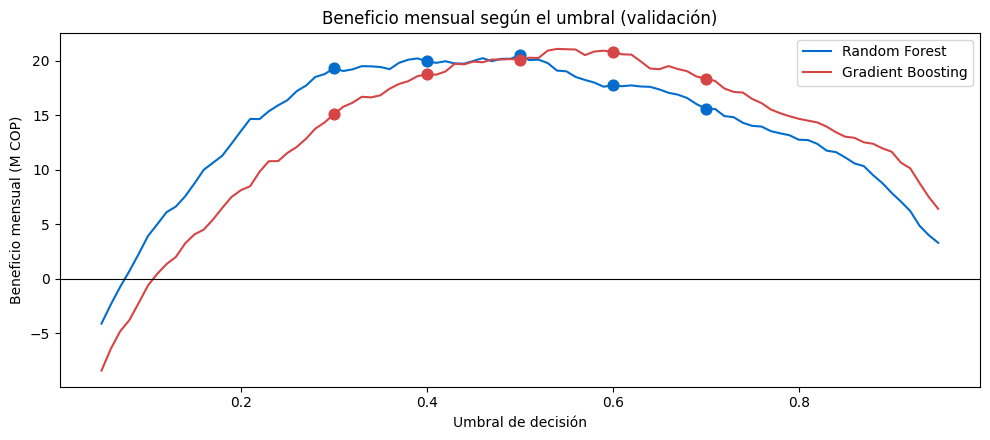

In [7]:
# Curva con todos los umbrales; los puntos son los cinco de la práctica
umbrales_curva = np.arange(0.05, 0.96, 0.01)
colores = {"Random Forest": "#026DCC", "Gradient Boosting": "#D64545"}

fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre in modelos:
    curva = []
    for umbral in umbrales_curva:
        recall, fall_out = tasas(y_val, prob_val[nombre], umbral)
        curva.append(beneficio_mensual(recall, fall_out) / 1e6)
    puntos = []
    for umbral in UMBRALES:
        recall, fall_out = tasas(y_val, prob_val[nombre], umbral)
        puntos.append(beneficio_mensual(recall, fall_out) / 1e6)
    ax.plot(umbrales_curva, curva, color=colores[nombre], label=nombre)
    ax.scatter(UMBRALES, puntos, color=colores[nombre], s=60, zorder=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Beneficio mensual (M COP)")
ax.set_title("Beneficio mensual según el umbral (validación)")
ax.legend()
plt.tight_layout()
plt.show()

* Al bajar el umbral se contacta a más clientes: sube el recall y baja la precisión. Al subirlo pasa lo contrario.
* El mejor umbral es **0,5 para el Random Forest** (COP 20,5 M al mes en validación) y **0,6 para el Gradient Boosting** (COP 20,8 M).
* En la curva se ve que cerca del máximo el beneficio cambia poco.

**Resultado en prueba.** Aplicamos los umbrales elegidos a los clientes de prueba y comparamos con contactar a todos. No hacer campaña da 0.

In [8]:
umbral_rf = umbral_elegido["Random Forest"]
umbral_gb = umbral_elegido["Gradient Boosting"]

politicas = {
    "Contactar a todos": (1.0, 1.0),
    "Random Forest": tasas(y_test, prob_test["Random Forest"], umbral_rf),
    "Gradient Boosting": tasas(y_test, prob_test["Gradient Boosting"], umbral_gb),
}

filas = []
for nombre in politicas:
    recall, fall_out = politicas[nombre]
    P = precision_banco(recall, fall_out)
    ve = valor_esperado(recall, fall_out)
    filas.append({
        "política": nombre,
        "contactados al año": round(N * (p_p * recall + p_n * fall_out)),
        "retenidos al año": round(r * N * p_p * recall),
        "precisión": P,
        "recall": recall,
        "valor esperado por cliente (COP)": round(ve),
        "â por contacto (COP)": round(a - (1 - P) * e),
        "ganancia anual (M COP)": 12 * beneficio_mensual(recall, fall_out) / 1e6,
    })
pd.DataFrame(filas).set_index("política").round(3)

,contactados al año,retenidos al año,precisión,recall,valor esperado por cliente (COP),â por contacto (COP),ganancia anual (M COP)
política,,,,,,,
Contactar a todos,20000,900,0.150,1.000,-8500,-8500,-170.000
Random Forest,3050,537,0.587,0.597,12706,83309,254.126
Gradient Boosting,3682,557,0.504,0.619,12139,65931,242.780


Con el **Random Forest y umbral 0,5**, en el banco de 20.000 clientes:
* Se contacta a **3.050 clientes al año** (unos 254 al mes) y se encuentra al 59,7% de los que se iban a ir.
* Se retiene a **537 clientes al año** y el churn baja de 15% a 12,3%.
* La campaña gana **COP 254 M al año** (COP 21,2 M al mes).
* Contactar a todos pierde COP 170 M al año, así que sin modelo lo mejor es no hacer campaña.
* El Gradient Boosting con umbral 0,6 gana COP 243 M al año.

**Incertidumbre.** La ganancia sale de solo 2.000 clientes de prueba. Hacemos bootstrapping con muestras pareadas, como en la práctica 4: remuestreamos los clientes de prueba $B = 1.000$ veces, con la misma muestra para los dos modelos. Con las diferencias $d_b$ de cada réplica calculamos el intervalo del 95% y el valor p:

$$p \approx 2 \cdot \min\left(\frac{\#\{d_b \le 0\}}{B},\ \frac{\#\{d_b \ge 0\}}{B}\right)$$

Un modelo es mejor si el intervalo excluye el 0 y la diferencia supera un umbral relevante, que fijamos en COP 12 M al año (COP 1 M al mes).

In [9]:
# Bootstrapping con muestras pareadas, como en la ayuda de prueba A/B del curso
rng = np.random.default_rng(SEED)
B = 1000
n_test = len(y_test)
prob_rf = prob_test["Random Forest"]
prob_gb = prob_test["Gradient Boosting"]

boot_rf = np.empty(B)
boot_gb = np.empty(B)
for b in range(B):
    idx = rng.integers(0, n_test, n_test)  # la misma muestra para los dos
    recall, fall_out = tasas(y_test[idx], prob_rf[idx], umbral_rf)
    boot_rf[b] = 12 * beneficio_mensual(recall, fall_out)
    recall, fall_out = tasas(y_test[idx], prob_gb[idx], umbral_gb)
    boot_gb[b] = 12 * beneficio_mensual(recall, fall_out)

# Ganancia anual con todos los clientes de prueba
ganancia = {}
for nombre in politicas:
    recall, fall_out = politicas[nombre]
    ganancia[nombre] = 12 * beneficio_mensual(recall, fall_out)
ganancia_rf = ganancia["Random Forest"]
ganancia_gb = ganancia["Gradient Boosting"]
ganancia_todos = ganancia["Contactar a todos"]

inferior, superior = np.percentile(boot_rf, [2.5, 97.5]) / 1e6
print("Ganancia anual del Random Forest:", round(ganancia_rf / 1e6, 1), "M COP")
print("Intervalo del 95%:", round(inferior, 1), "a", round(superior, 1), "M COP")

observada = {
    "RF - Contactar a todos": ganancia_rf - ganancia_todos,
    "RF - Gradient Boosting": ganancia_rf - ganancia_gb,
}
diferencias = {
    "RF - Contactar a todos": boot_rf - ganancia_todos,
    "RF - Gradient Boosting": boot_rf - boot_gb,
}
umbral_relevante = 12  # M COP al año (COP 1 M al mes)

filas = []
for nombre in diferencias:
    d = diferencias[nombre] / 1e6
    inferior, superior = np.percentile(d, [2.5, 97.5])
    p_boot = min(1.0, 2 * min(np.mean(d <= 0), np.mean(d >= 0)))
    filas.append({"comparación": nombre, "diferencia": observada[nombre] / 1e6,
                  "IC 2,5 %": inferior, "IC 97,5 %": superior,
                  "p bootstrapping": p_boot})

print("Diferencias de ganancia anual (M COP):")
resumen = pd.DataFrame(filas).set_index("comparación")
resumen["excluye 0"] = (resumen["IC 2,5 %"] > 0) | (resumen["IC 97,5 %"] < 0)
grande = resumen["diferencia"].abs() >= umbral_relevante
resumen["relevante"] = resumen["excluye 0"] & grande
resumen.round(3)

Ganancia anual del Random Forest: 254.1 M COP
Intervalo del 95%: 228.0 a 279.9 M COP
Diferencias de ganancia anual (M COP):


,diferencia,"IC 2,5 %","IC 97,5 %",p bootstrapping,excluye 0,relevante
comparación,,,,,,
RF - Contactar a todos,424.126,397.989,449.929,0.000,True,True
RF - Gradient Boosting,11.346,-3.753,26.792,0.152,False,False


* La ganancia del Random Forest está entre **COP 228 M y 280 M** al año, con 95% de confianza.
* El modelo le gana a contactar a todos en todas las réplicas, por entre COP 398 M y 450 M al año.
* El Random Forest gana COP 11 M al año más que el Gradient Boosting, pero el intervalo (−3,8 M a 26,8 M) incluye el 0 (p = 0,15). **No hay evidencia de que uno gane más que el otro.** Seguimos con el Random Forest, el modelo elegido en el notebook 2.

### 5.7 Inversión, punto de equilibrio y ROI

Armamos el presupuesto por rubros como en la práctica 4: un científico de datos de tiempo completo y un ingeniero de datos y ML de medio tiempo durante 6 meses, más la nube y 10% de contingencia.
* **Salario.** COP 10 M al mes, entre los COP 6,1 M de [Indeed](https://co.indeed.com/career/data-scientist/salaries) y los 13,1 M de [Levels.fyi](https://www.levels.fyi/es/t/data-scientist/locations/colombia), más 45% de [prestaciones](https://www.gerencie.com/porcentajes-prestaciones-sociales.html).
* **Nube.** US\$200 al mes.
* **Duración.** Según [Gartner](https://www.gartner.com/en/newsroom/press-releases/2024-05-07-gartner-survey-finds-generative-ai-is-now-the-most-frequently-deployed-ai-solution-in-organizations), un proyecto de IA tarda unos 8 meses en llegar a producción. Usamos 6 porque el modelo ya existe.

In [10]:
meses_impl = 6                   # meses de implementación
persona_mes = 10_000_000 * 1.45  # salario más 45% de prestaciones
nube_mes = 200 * 3_238           # US$200 al mes con la TRM de noviembre

rubros = {
    "Científico de datos": meses_impl * persona_mes,
    "Ingeniero de datos y ML (medio tiempo)": meses_impl * 0.5 * persona_mes,
    "Nube": meses_impl * nube_mes,
}
rubros["Contingencia (10%)"] = 0.10 * sum(rubros.values())
I_proy = sum(rubros.values())

presupuesto = pd.Series(rubros)
presupuesto["Inversión total"] = I_proy
(presupuesto / 1e6).round(1).to_frame("M COP")

,M COP
Científico de datos,87.0
Ingeniero de datos y ML (medio tiempo),43.5
Nube,3.9
Contingencia (10%),13.4
Inversión total,147.8


El beneficio mensual $B$ es el de la campaña menos la operación:

$$B = \frac{N \cdot \text{Valor esperado} - O}{12}$$

El punto de equilibrio es el mes en el que el ROI llega a 0, y el ROI a 12 meses usa el beneficio de un año:

$$t^* = \frac{I_{\text{proy}}}{B} \qquad\qquad \text{ROI} = \frac{\text{Retorno} - \text{Inversión}}{\text{Inversión}} = \frac{12B - I_{\text{proy}}}{I_{\text{proy}}}$$

Los meses se cuentan desde que el modelo empieza a operar.

In [11]:
filas = []
for nombre in ["Random Forest", "Gradient Boosting"]:
    recall, fall_out = politicas[nombre]
    B_mes = beneficio_mensual(recall, fall_out) - O / 12
    filas.append({
        "modelo": nombre,
        "umbral": umbral_elegido[nombre],
        "campaña al mes (M COP)": beneficio_mensual(recall, fall_out) / 1e6,
        "operación al mes (M COP)": O / 12 / 1e6,
        "B (M COP)": B_mes / 1e6,
        "t* (meses)": I_proy / B_mes,
        "ROI a 12 meses": (12 * B_mes - I_proy) / I_proy,
    })
pd.DataFrame(filas).set_index("modelo").round(2)

,umbral,campaña al mes (M COP),operación al mes (M COP),B (M COP),t* (meses),ROI a 12 meses
modelo,,,,,,
Random Forest,0.5,21.18,4.17,17.01,8.69,0.38
Gradient Boosting,0.6,20.23,4.17,16.06,9.20,0.30


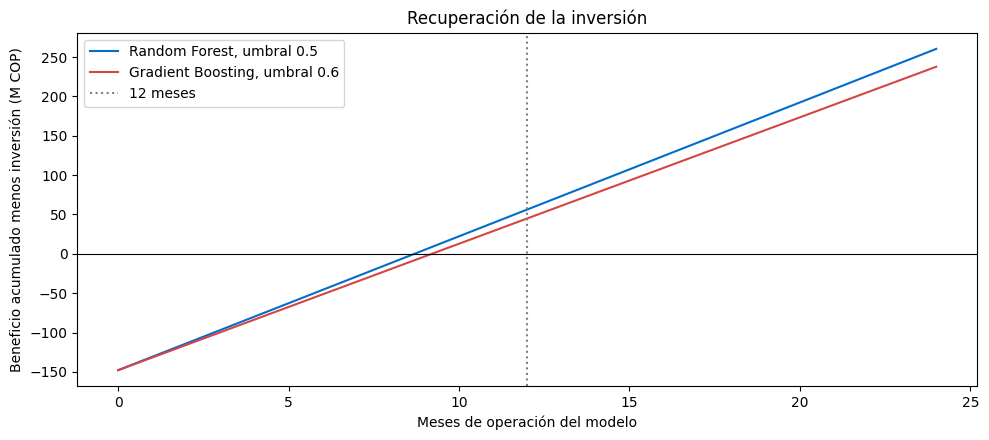

In [12]:
meses = np.arange(0, 25)

fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre in ["Random Forest", "Gradient Boosting"]:
    recall, fall_out = politicas[nombre]
    B_mes = beneficio_mensual(recall, fall_out) - O / 12
    etiqueta = nombre + ", umbral " + str(umbral_elegido[nombre])
    acumulado = (meses * B_mes - I_proy) / 1e6
    ax.plot(meses, acumulado, color=colores[nombre], label=etiqueta)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(12, color="gray", linestyle=":", label="12 meses")
ax.set_xlabel("Meses de operación del modelo")
ax.set_ylabel("Beneficio acumulado menos inversión (M COP)")
ax.set_title("Recuperación de la inversión")
ax.legend()
plt.tight_layout()
plt.show()

* Con el Random Forest, $B$ es **COP 17,0 M al mes** y la inversión de COP 148 M se recupera en **8,7 meses de operación**, cerca del mes 15 si se cuentan los 6 de implementación.
* El **ROI a 12 meses es de 38%**: en un año de operación el modelo devuelve la inversión y deja unos COP 56 M más.
* El Gradient Boosting se recupera en 9,2 meses, con un ROI a 12 meses de 30%.

### 5.8 Recuperar la inversión en 12 meses

Con $M$ clientes que abandonan al mes, el beneficio mensual también se puede escribir con la precisión $P$ y el recall $R$:

$$B = R \cdot M \left(rV - \frac{c}{P}\right) - \frac{O}{12}, \qquad M = \frac{N \cdot p(p)}{12} = 250$$

Para recuperar la inversión en $k$ meses se necesita $k \cdot B \ge I_{\text{proy}}$, así que el recall mínimo es

$$R_{\min} = \frac{I_{\text{proy}}/k + O/12}{M\left(rV - c/P\right)}$$

Es la fórmula de la práctica 4 más el costo de operación. Usamos $k = 12$.

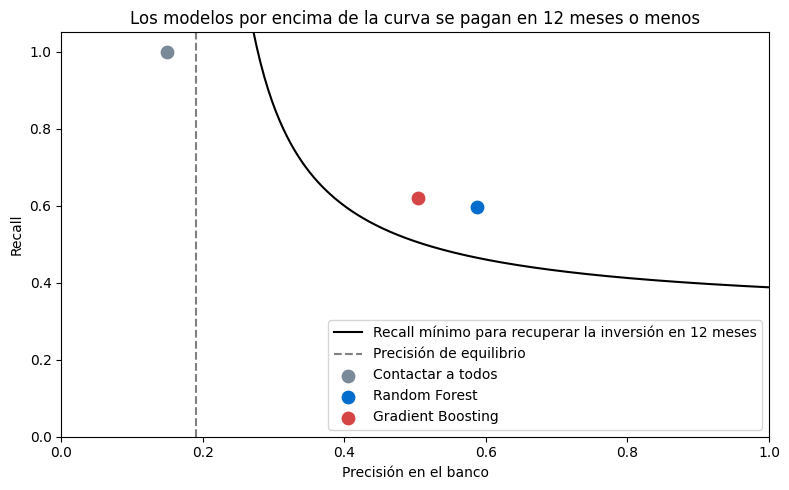

In [13]:
k = 12                          # meses para recuperar la inversión
M = N * p_p / 12                # clientes que abandonan al mes
costo_mensual = I_proy / k + O / 12

# La curva solo existe por encima de la precisión de equilibrio
precisiones = np.linspace(P_e + 0.005, 1, 300)
R_min = costo_mensual / (M * (r * V - c / precisiones))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(precisiones, R_min, color="black",
        label="Recall mínimo para recuperar la inversión en 12 meses")
ax.axvline(P_e, color="gray", linestyle="--", label="Precisión de equilibrio")
colores["Contactar a todos"] = "#7A8A99"
for nombre in politicas:
    recall, fall_out = politicas[nombre]
    P = precision_banco(recall, fall_out)
    ax.scatter(P, recall, color=colores[nombre], s=80, zorder=3, label=nombre)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Precisión en el banco")
ax.set_ylabel("Recall")
ax.set_title("Los modelos por encima de la curva se pagan en 12 meses o menos")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

* El Random Forest y el Gradient Boosting quedan por encima de la curva: los dos se pagan en menos de 12 meses.
* Contactar a todos queda a la izquierda de $P_e$: no se paga nunca.

**A partir de qué valor.** Despejamos cada variable de la misma condición para el Random Forest, dejando las demás en su valor base.

In [14]:
recall_rf, fall_out_rf = politicas["Random Forest"]
P_rf = precision_banco(recall_rf, fall_out_rf)

# Condición: R * M * (rV - c/P) >= costo_mensual.
# Despejamos una variable a la vez, con las demás en su valor base.
minimo = costo_mensual / (M * recall_rf)   # lo mínimo que debe valer rV - c/P

recall_min = costo_mensual / (M * (r * V - c / P_rf))
precision_min = c / (r * V - minimo)
costo_max = P_rf * (r * V - minimo)
efectividad_min = (minimo + c / P_rf) / V

print("Recall mínimo:", round(recall_min, 3), "| tiene", round(recall_rf, 3))
print("Precisión mínima:", round(precision_min, 3), "| tiene", round(P_rf, 3))
print("Costo máximo por contacto:", round(costo_max), "| caso base", c)
print("Efectividad mínima:", round(efectividad_min, 3), "| caso base", r)

Recall mínimo: 0.465 | tiene 0.597
Precisión mínima: 0.402 | tiene 0.587
Costo máximo por contacto: 58457 | caso base 40000
Efectividad mínima: 0.255 | caso base 0.3


* Con su precisión de 58,7%, el modelo necesita un recall de al menos **46,5%**; tiene 59,7%.
* Con su recall, necesita una precisión de al menos **40,2%**.
* Cada contacto puede costar hasta **COP 58.457**; el caso base es COP 40.000.
* **La oferta tiene que convencer a más del 25,5%** de los clientes en riesgo. El caso base es 30%, así que es el supuesto con menos margen.

### 5.9 Limitaciones

1. **Los datos no son colombianos.** El modelo se entrenó con clientes de Francia, Alemania y España. Habría que reentrenarlo con datos del banco antes de usarlo.
2. **Pasar de 20% a 15% de churn** supone que los clientes que se van, y los que se quedan, se parecen en los dos bancos.
3. **No sabemos cuántos aceptan la oferta.** Supusimos que la oferta convence al 30% de los clientes que se iban a ir, pero eso no lo medimos. Si convence a menos del 25,5%, el modelo no alcanza a pagarse en un año (sección 5.8). Además, puede que los que más quieren irse sean los más difíciles de retener.
4. **El valor de un cliente es su ingreso de un año.** No restamos lo que cuesta atenderlo, lo que sobrestima el valor, ni contamos los años siguientes, lo que lo subestima.
5. **Algunos supuestos tienen fuentes débiles.** El 15% de churn no tiene un estudio detrás, el costo por contacto sale de precios de proveedores, y la operación, la nube y las llamadas por hora son supuestos nuestros. Si cada contacto termina costando más de COP 58.457, el modelo ya no se paga en un año.
6. **El modelo se degrada con el tiempo.** Habría que monitorearlo y reentrenarlo.
7. **Datos personales y discriminación.** El banco necesita autorización para usar los datos de sus clientes (Ley 1581 de 2012), y como el modelo usa el género y la edad, hay que revisar que la campaña no discrimine.

### 5.10 Conclusiones y recomendaciones

* En un banco de 20.000 clientes con 15% de churn, el Random Forest con umbral 0,5 retiene a unos **537 clientes al año** y baja el churn de 15% a 12,3%.
* La campaña deja **COP 254 M al año** (entre 228 M y 280 M con 95% de confianza): COP 12.706 por cliente evaluado y COP 83.309 por cliente contactado. Sin modelo, lo mejor es no hacer campaña, porque contactar a todos pierde COP 170 M al año.
* Con una inversión de COP 148 M y COP 50 M al año de operación, la inversión se recupera en **8,7 meses de operación** y el **ROI a 12 meses es de 38%**.
* El supuesto con menos margen es la efectividad de la oferta: el proyecto se paga en su primer año solo si convence a más del 25,5% de los clientes en riesgo, y el caso base es 30%.

**Recomendación.** Recomendamos usar el Random Forest con umbral de 0,5, pero antes hay que tener en cuenta cuatro cosas:
1. **Datos europeos.** Hay que reentrenar y validar el modelo con datos de un banco colombiano.
2. **No sabemos cuántos aceptan la oferta.** Hay que medirlo: si son menos del 25,5%, el modelo no se paga en un año.
3. **Supuestos inciertos.** El 15% de churn y el costo por contacto tienen fuentes débiles; si cada contacto cuesta más de COP 58.457, el modelo no se paga en un año.
4. **Datos personales y equidad.** El banco necesita autorización de los clientes para usar sus datos (Ley 1581), y como el modelo usa el género y la edad, hay que revisar que la campaña no discrimine.